In [3]:
%load_ext autoreload
%autoreload 2

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import xarray as xr

from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from cmcrameri import cm
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from fast_o3_iv import utils
from fast_o3_iv.config import PROCESSED_DATA_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
ds = xr.open_dataset(PROCESSED_DATA_DIR / "figure_data" / "Figure5_local_metrics_fields_and_risk_scores.nc")

In [5]:
# helper funcs and plot settings

utils.set_matplotlib_font("Arial")
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
color = 'black'

mpl.rcParams.update({
    'axes.edgecolor': color,      
    'xtick.color': color,         
    'ytick.color': color,         
    'xtick.labelcolor': color,    
    'ytick.labelcolor': color,    
    'grid.color': color,          
    'axes.labelcolor': color,    
    'axes.titlecolor': color,    
})

mpl.rcParams.update({
    'font.size': 8, 
    'axes.titlesize': 10, 
    'axes.labelsize': 10,
    'xtick.labelsize': 8, 
    'ytick.labelsize': 8, 
    'legend.fontsize': 8,
    'figure.titlesize': 10
})

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb



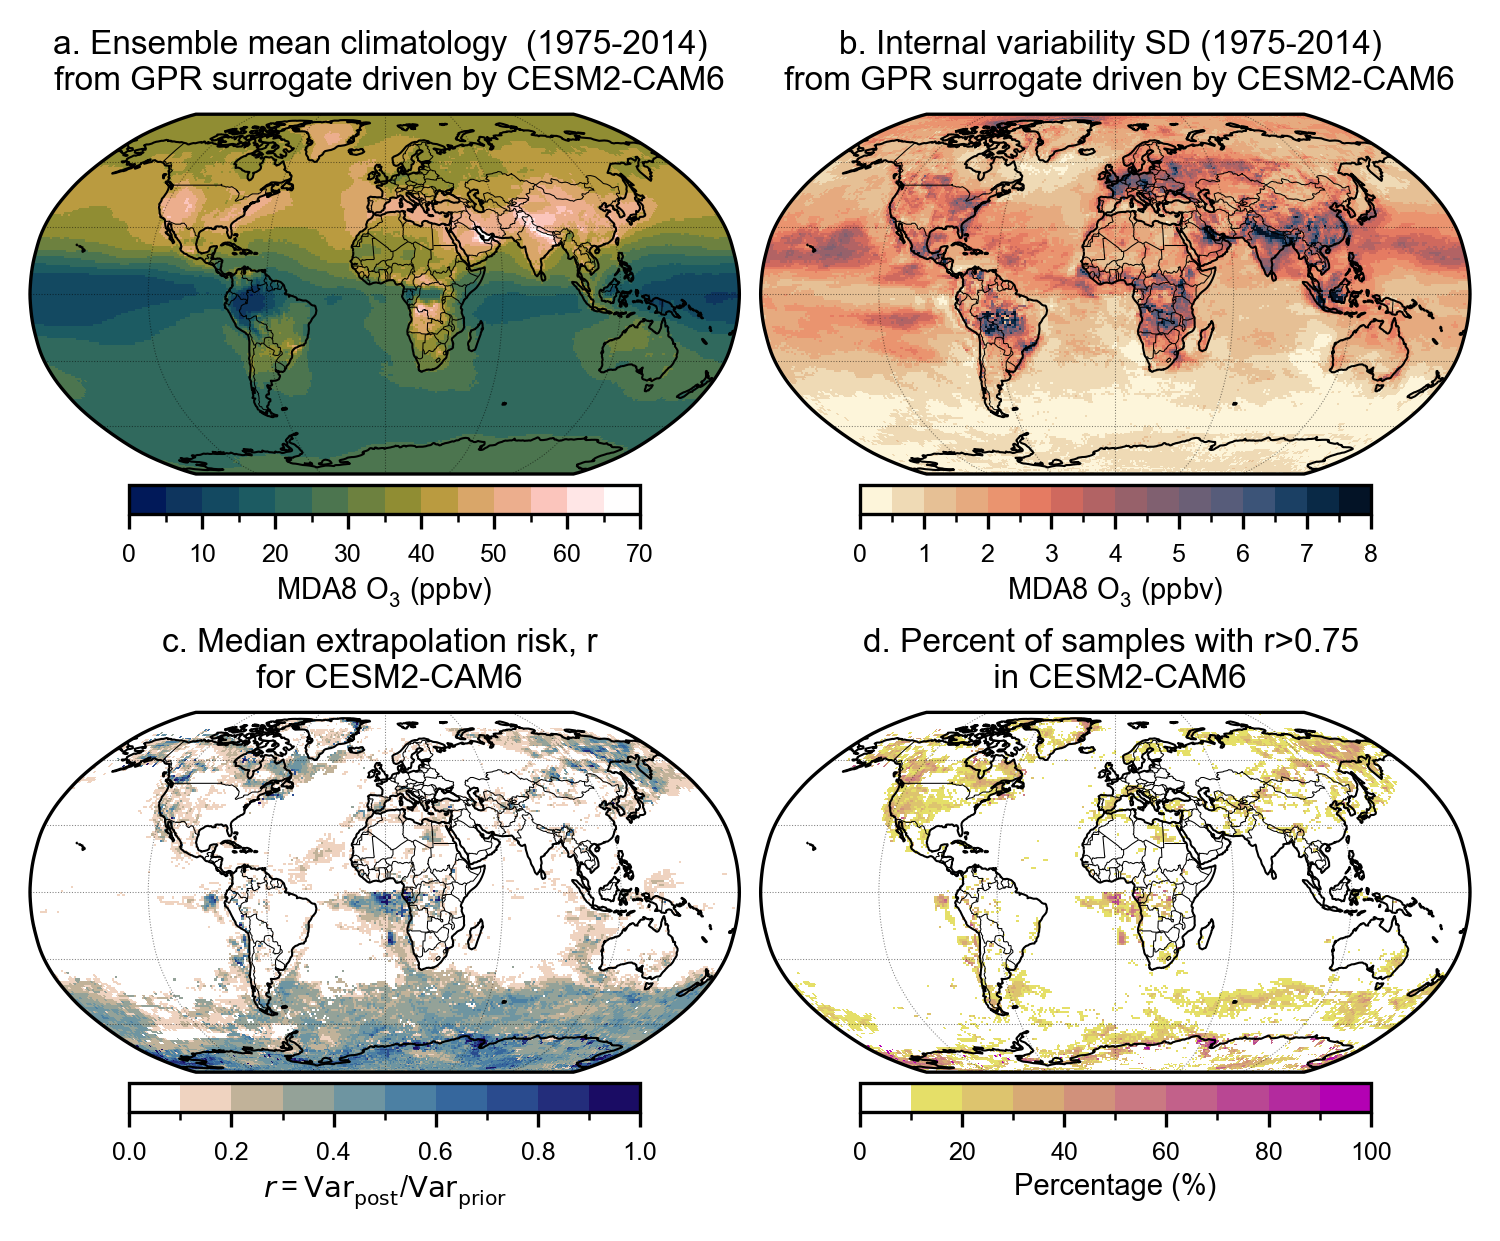

In [6]:
# create the figure

fig_width_in = 6
fig_height_in = 4.8

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(2, 2, top=0.90, bottom=0.10, left=0.08, right=0.88,
               hspace=0.08, wspace=0.03)
               

proj = ccrs.Robinson(central_longitude=0)
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)
ax3 = fig.add_subplot(gs1[1, 0], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4]
titles= ["a. Ensemble mean climatology  (1975-2014) \n from GPR surrogate driven by CESM2-CAM6", 
         "b. Internal variability SD (1975-2014) \n from GPR surrogate driven by CESM2-CAM6",
         "c. Median extrapolation risk, r \n for CESM2-CAM6",
         "d. Percent of samples with r>0.75 \n in CESM2-CAM6"]


for ax, t in zip([ax1, ax2, ax3, ax4], titles):
    ax.set_title(t, color="black", fontsize=8)
    style_map(ax)


# predicted climatology

vmax = 70
vmin = 0
step = 5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.batlowW
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m1 = ds['clim_pred'].plot.pcolormesh(
    ax=ax1, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax1, m1, label="MDA8 O$_3$ (ppbv)")


# predicted standard deviation 

vmax = 8
vmin = 0
step = 0.5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.lipari_r
colors = base(np.linspace(0, 1, n_bins))
cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m2 = ds['sd_pred'].plot.pcolormesh(
    ax=ax2, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax2, m2, label="MDA8 O$_3$ (ppbv)")

# median risk
vmax = 1
vmin = 0
step = 0.1
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.lapaz_r
colors = base(np.linspace(0, 1, n_bins))

# force the first color to white (RGBA)
colors[0] = (1.0, 1.0, 1.0, 1.0)

cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m3 = ds['risk_median'].plot.pcolormesh(
    ax=ax3, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()
)
add_panel_cbar(fig, ax3, m3,
               label=r"$\mathit{r} = \mathrm{Var}_{\mathrm{post}} / \mathrm{Var}_{\mathrm{prior}}$")


# r frequency
vmax = 100
vmin = 0
step = 10
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = cm.buda_r
colors = base(np.linspace(0, 1, n_bins))

# force the first color to white (RGBA)
colors[0] = (1.0, 1.0, 1.0, 1.0)

cmap = matplotlib.colors.ListedColormap(colors)
norm = matplotlib.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m4 = ds['risk_frequency'].plot.pcolormesh(
    ax=ax4, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()
)
add_panel_cbar(fig, ax4, m4,
               label="Percentage (%)")

#for ax in [ax3, ax4]:
    #add_hatch(ax)
